# Learning the Loop #104 — Overfitting vs. Underfitting (practical)

The dataset is fixed and the only randomness is the split seeds, so you should get exactly the numbers in the article (Table 1, Table 2, and the in-range breakdown).

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

In [20]:
N_TRAIN, REPS = 60, 200

## 1. Data
442 real patients. Feature: BMI, standardized. Target: disease progression after one year.

In [21]:
data = load_diabetes()
x_all = data.data[:, 2]
y_all = data.target
x_all = (x_all - x_all.mean()) / x_all.std()
print(len(x_all), 'patients')

442 patients


## 2. Model and error
Polynomial regression of degree `d`, fitted by least squares. Degree 0 is the mean-only predictor.

In [22]:
def fit(x, y, d):
    if d == 0:
        c = y.mean()
        return lambda z: np.full_like(z, c, dtype=float)
    return np.polynomial.Polynomial.fit(x, y, d)

def mse(p, x, y):
    return float(np.mean((p(x) - y) ** 2))

## 3. One split: underfit, good fit, overfit (Figure 1)

degree 0: train MSE 6,999   test MSE 5,791
degree 1: train MSE 4,313   test MSE 3,965
degree 8: train MSE 4,043   test MSE 1,114,784


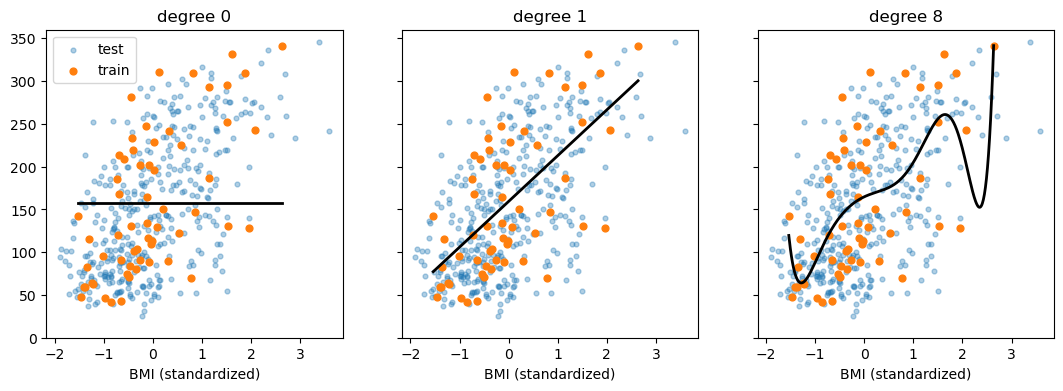

In [23]:
a, b, ya, yb = train_test_split(x_all, y_all, train_size=N_TRAIN, random_state=0)
grid = np.linspace(a.min(), a.max(), 400)
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, deg in zip(axes, (0, 1, 8)):
    p = fit(a, ya, deg)
    ax.scatter(b, yb, s=12, alpha=0.35, label='test')
    ax.scatter(a, ya, s=24, label='train')
    ax.plot(grid, p(grid), color='black', lw=2)
    ax.set_ylim(0, 360)
    ax.set_title(f'degree {deg}')
    ax.set_xlabel('BMI (standardized)')
    print(f'degree {deg}: train MSE {mse(p, a, ya):,.0f}   test MSE {mse(p, b, yb):,.0f}')
axes[0].legend(); plt.show()

## 4. Sweep flexibility over 200 random splits (Table 1, Figure 2)
Medians, so one unlucky split can't dominate.

In [24]:
def sweep(n, degrees, reps=REPS):
    tr = {d: [] for d in degrees}
    te = {d: [] for d in degrees}
    for s in range(reps):
        a, b, ya, yb = train_test_split(x_all, y_all, train_size=n, random_state=s)
        for d in degrees:
            p = fit(a, ya, d)
            tr[d].append(mse(p, a, ya))
            te[d].append(mse(p, b, yb))
    return tr, te

DEGREES = list(range(0, 11))
tr, te = sweep(N_TRAIN, DEGREES)
print(f"{'deg':>3} {'train MSE':>12} {'test MSE':>14}")
for d in DEGREES:
    print(f'{d:>3} {np.median(tr[d]):>12,.0f} {np.median(te[d]):>14,.0f}')

deg    train MSE       test MSE
  0        5,881          6,002
  1        3,859          3,990
  2        3,822          4,055
  3        3,752          4,173
  4        3,727          4,456
  5        3,658          5,481
  6        3,546         17,095
  7        3,534         66,724
  8        3,494        539,145
  9        3,443      4,096,861
 10        3,390     41,961,700


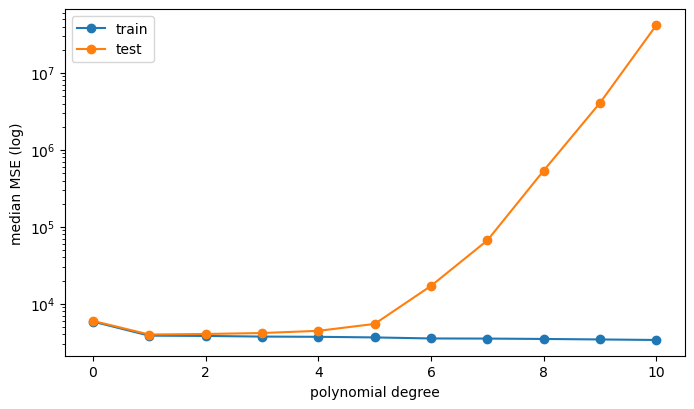

In [25]:
plt.figure(figsize=(8, 4.5))
plt.plot(DEGREES, [np.median(tr[d]) for d in DEGREES], marker='o', label='train')
plt.plot(DEGREES, [np.median(te[d]) for d in DEGREES], marker='o', label='test')
plt.yscale('log'); plt.xlabel('polynomial degree'); plt.ylabel('median MSE (log)')
plt.legend(); plt.show()

## 5. Does more data help? (Table 2, Figure 3)
Same degree-8 model, growing training set.

In [28]:
for n in [15, 30, 60, 120, 240]:
    t, e = sweep(n, [8])
    print(f'n={n:>4}  train {np.median(t[8]):>8,.0f}   test {np.median(e[8]):>16,.0f}')

n=  15  train    1,644   test   12,500,672,624
n=  30  train    2,811   test       48,550,476
n=  60  train    3,494   test          539,145
n= 120  train    3,732   test            9,693
n= 240  train    3,775   test            4,432


## 6. Where does the test error come from?
Split the test patients into those *inside* the training BMI range and those *outside* it.

In [29]:
inr = {d: [] for d in (1, 6, 8, 10)}
outside = []
for s in range(REPS):
    a, b, ya, yb = train_test_split(x_all, y_all, train_size=N_TRAIN, random_state=s)
    inside = (b >= a.min()) & (b <= a.max())
    outside.append(1 - inside.mean())
    for d in inr:
        p = fit(a, ya, d)
        inr[d].append(float(np.mean(((p(b) - yb) ** 2)[inside])))
print(f'test patients outside training range (median share): {np.median(outside):.3f}')
for d in inr:
    print(f'degree {d:>2}: test MSE inside range = {np.median(inr[d]):,.0f}')

test patients outside training range (median share): 0.029
degree  1: test MSE inside range = 4,061
degree  6: test MSE inside range = 4,341
degree  8: test MSE inside range = 4,569
degree 10: test MSE inside range = 4,966


## 7. Experiments to try
- Change `N_TRAIN` to 30 or 120 and re-run sections 4 and 6. Where does the best degree move?
- Swap BMI for another column of `data.data` (try index 8, `s5`). Is the best degree still 1?
- Compute the test error *only inside* the training range for every degree, and plot it next to the all-patients curve. How much of the overfitting gap disappears?